# **ACENET: Introduction to Machine Learning**
## Session 2: Hands-on Machine Learning with scikit-learn
##### Arora Abir
This notebook contains the short, hands-on examples for Session 2.  
We will work through each method step by step, run the code together, look at the output, and then try a short exercise.


---



### How to use this notebook

The instructor will work through the cells live with the group. Learners will follow along, run the same
cells, change values, and try each exercise before moving on to the next method.

This notebook runs in **Google Colab** / **Jupyter Notebook** with no setup required. Every dataset is created inside the
notebook, so there are no files to download.

## **Why are we using scikit-learn?**

Python has several libraries for machine learning.
For example, **PyTorch** is very powerful and is widely used for deep learning and neural networks. However, for this session, we'll be using **scikit-learn** because:
- It gives us simple, ready-to-use versions of many classical machine-learning methods such as linear regression, decision trees, random forests, and K-nearest neighbours.
- It also uses a consistent workflow across many models such as: create the model, use `.fit()` to train it, and use `.predict()` to make predictions which makes it easier to learn the basic machine-learning process without adding too much setup or extra code.


## Libraries we will use

1. **pandas**  
Pandas helps us work with data in table form. Its main table structure is called a **DataFrame**. We will use DataFrames to store our small datasets and to select the columns that will become the model inputs and outputs.

2. **matplotlib**  
Matplotlib is a plotting library. We will use it to draw simple graphs so we can see patterns in the data before and after fitting a model. This also helps us notice unusual values that may affect the model.

3. **scikit-learn**  
Scikit-learn provides the machine-learning models we will use in this session. For the first example, we import `LinearRegression` from `sklearn.linear_model`.


In [ ]:
# pandas is used for data tables
import pandas as pd

# matplotlib is used for plotting
import matplotlib.pyplot as plt

# LinearRegression is the first machine-learning model technique we will use
from sklearn.linear_model import LinearRegression


# 1. Linear Regression

**Regression** is a machine-learning task where we want to predict a **number**, such as house price, exam score, or heating use, where **Linear Regression** is one method for a regression task. What makes it *linear* is the assumption it makes: that the relationship between the input features and the target can be drawn as a **straight line**. If the real pattern is strongly curved, a straight line will not describe it well, and a different method would suit the data better.

For example, linear regression can be used to:
1. study how house size relates to house price
2. how study time relates to exam score, or
3.  how outdoor temperature relates to heating use etc.

For this first example, we will keep things very small: **outdoor temperature will be our input, and heating use will be the value we want to predict**.


## 1.1 Create a small dataset

We will use a tiny **synthetic** dataset so we can see every value clearly.

Before running any model, look at the numbers and think:

**As the temperature gets colder, what seems to happen to heating use?**


In [ ]:
# pd.DataFrame creates a table with named columns
data = pd.DataFrame({
    'Temperature': [8, 4, 0, -4, -8, -12],
    'Heating':     [22, 28, 35, 44, 54, 65]
})

# Display the table
data


,Temperature,Heating
0,8,22
1,4,28
2,0,35
3,-4,44
4,-8,54
5,-12,65


## 1.2 Plot the data

Before fitting a model, it is useful to look at the data first.  
A scatter plot lets us see whether there is a visible relationship between the two variables.


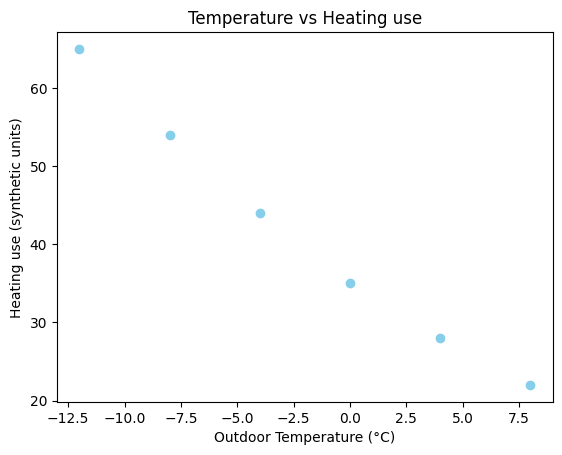

In [ ]:
# Put temperature on the x-axis and heating use on the y-axis
plt.scatter(data['Temperature'], data['Heating'], color=['skyblue'])

# Add labels so the plot is easy to understand
plt.xlabel('Outdoor Temperature (°C)')
plt.ylabel('Heating use (synthetic units)')
plt.title('Temperature vs Heating use')

# Display the plot
plt.show()


### What does the plot show?

The points follow a clear trend: **colder temperatures are associated with higher heating use**.

The points do not sit perfectly on one straight line, but the pattern is close enough that linear regression is a reasonable simple model to try.


## 1.3 Choose the input and the target

In scikit-learn, we usually use:

- **X** for the input feature(s)
- **y** for the target we want to predict

Here, **X is temperature** and **y is heating use**.

### Why do we use double brackets for X?

Scikit-learn expects **X to be a two-dimensional (2D) table**:

- Each **row** is one example (one day).
- Each **column** is one input feature.

Here we have **6 days and 1 feature (Temperature)**, so X is a table of 6 rows and 1 column.

`data[['Temperature']]` keeps that table shape. `data['Temperature']` with single brackets would give a one-dimensional list of values instead, and the model would not accept it.

The target `y` is different: single brackets are fine there, because y only needs one answer per day.


In [ ]:
# Select the input feature.
# Double brackets keep X as a 2D table:
# rows = examples, columns = features.

X = data[['Temperature']]

X


,Temperature
0,8
1,4
2,0
3,-4
4,-8
5,-12


In [ ]:
# Select the target column we want the model to predict.
y = data['Heating']

y


,Heating
0,22
1,28
2,35
3,44
4,54
5,65


## 1.4 Create and train the model

First, we create an empty `LinearRegression` model.

Then we use `.fit(X, y)` to train it.

Here, `.fit()` means: **Learning the relationship between the input X and the target y from the examples we provided.**

### How does the model choose the line?

Many different straight lines could be drawn through our data. So how does Linear Regression choose the best one?

For each example, the model:

1. Finds the difference between the **actual value** and the **predicted value**.
2. Squares that difference.
3. Adds up the squared errors from all examples.

For example, if the actual heating use is **30**, but the line predicts **28**:

**Error = 30 − 28 = 2**

**Squared error = 2 × 2 = 4**

The model chooses the line that makes the **total squared error as small as possible**.

This is called the **Least Squares** method.

Why do we square the errors? Because squaring does two useful things:

- Squaring makes the errors non-negative, so positive and negative errors cannot cancel each other out.
- Larger errors become much bigger when squared, so they have a greater impact on the total.

When we run `.fit(X, y)`, scikit-learn finds this line for us.

In [ ]:
# Create the linear regression model
model = LinearRegression()

model


LinearRegression()

In [ ]:
# Train the model using our input X and target y
model.fit(X, y)


LinearRegression()

## 1.5 Make a prediction

Now we can give the trained model a new temperature.

Before running the prediction, guess:

**At −15 °C, would you expect the heating use to be higher or lower than it was at −12 °C?**


In [ ]:
# Create a new one-row table containing the temperature we want to predict for
new_day = pd.DataFrame({
    'Temperature': [-15]
})

new_day


,Temperature
0,-15


In [ ]:
# predict() uses the relationship learned during fit()
prediction = model.predict(new_day)

print("Predicted heating use:", round(prediction[0], 1))


Predicted heating use: 69.4


### What does the result mean?

The model predicts about **69.4 heating units** at **−15 °C**.

The model did not see −15 °C in the original data. It used the overall relationship it learned from the six examples to estimate a new value.


## 1.6 Plot the fitted line

Now we will draw the original data, the line learned by the model, and the new prediction on the same graph.


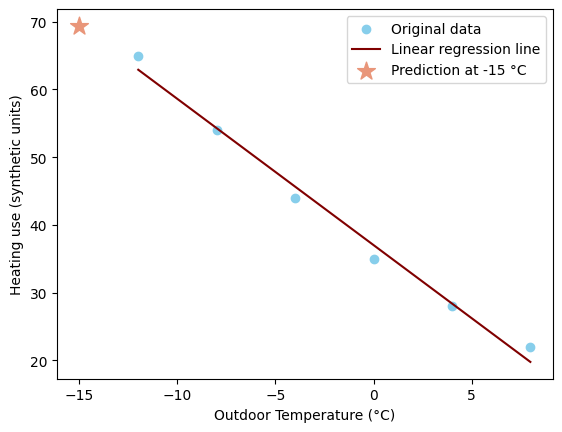

In [ ]:
# Plot the original data points
plt.scatter(
    data['Temperature'],
    data['Heating'],
    color='skyblue',
    label='Original data'
)

# Plot the values predicted by the model for the original temperatures
plt.plot(
    data['Temperature'],
    model.predict(X),
    color='maroon',
    label='Linear regression line'
)

# Add the new prediction as a star
plt.scatter(
    [-15],
    [prediction[0]],
    marker='*',
    s=180,
    color='Darksalmon',
    label='Prediction at -15 °C'
)

plt.xlabel('Outdoor Temperature (°C)')
plt.ylabel('Heating use (synthetic units)')
plt.legend()
plt.show()


### What does this graph show?

The line summarizes the overall relationship learned by the model: **as temperature decreases, predicted heating use increases**.

The star is the new prediction at −15 °C. Because −15 °C is just outside the temperatures in our small dataset, we should remember that predictions outside the observed range should be treated with care.


# Exercise 1: Try a different temperature

Before running any new code, answer these questions:

1. If the temperature changes from **−15 °C to −20 °C**, do you expect the predicted heating use to go up or down?
2. Which method should we use to get the prediction: `.fit()` or `.predict()`?
3. Try **−20 °C**, **−5 °C**, and **6 °C**. What changes in the prediction?
4. Does the direction of the change match the trend we saw in the graph?


In [ ]:
# Try the exercise here.
# Change the temperature value and run the cell.

try_day = pd.DataFrame({
    'Temperature': [-20]
})

# round() to 1 decimal place keeps the printed answer readable
print("Predicted heating use:", round(model.predict(try_day)[0], 1))

Predicted heating use: 80.2


## 1.7 What happens when there is an outlier?

An **outlier** is a value that is very different from the rest of the data.

Suppose we suddenly add this measurement:

**0 °C → 95 heating units**

Before running the next cells, predict what you think will happen to the fitted line.


In [ ]:
# Add one unusual value to the original dataset
data_outlier = pd.concat([
    data,
    pd.DataFrame({
        'Temperature': [0],
        'Heating': [95]
    })
], ignore_index=True)

data_outlier


,Temperature,Heating
0,8,22
1,4,28
2,0,35
3,-4,44
4,-8,54
5,-12,65
6,0,95


In [ ]:
# Create a second linear regression model
outlier_model = LinearRegression()

# Train this model using the dataset that contains the outlier
outlier_model.fit(
    data_outlier[['Temperature']],
    data_outlier['Heating']
)


LinearRegression()

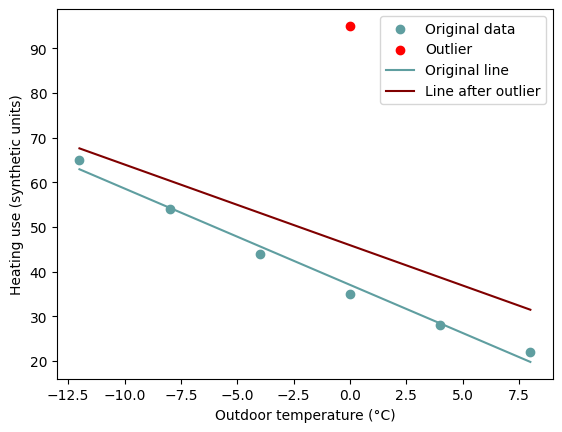

In [ ]:
# Plot the original observations
plt.scatter(
    data['Temperature'],
    data['Heating'],
    color='cadetblue',
    label='Original data'
)

# Plot the unusual observation
plt.scatter(
    [0],
    [95],
    color='red',
    label='Outlier'
)

# Plot the line learned from the original dataset
plt.plot(
    data['Temperature'],
    model.predict(X),
    color='cadetblue',
    label='Original line'
)

# Plot the line learned after adding the outlier
plt.plot(
    data['Temperature'],
    outlier_model.predict(X),
    color='maroon',
    label='Line after outlier'
)

plt.xlabel('Outdoor temperature (°C)')
plt.ylabel('Heating use (synthetic units)')
plt.legend()
plt.show()


### What changed?

The fitted line moved after we added the unusual data point.

But **why did it move?**

Remember that Linear Regression minimizes the **total squared error**, and squaring makes a large error count far more than a small one.

Look at our actual example. For the original six points, the total squared error was about **16.4**.

Now we add one unusual observation:

- Temperature = **0 °C**
- Actual heating use = **95**
- What the original line predicted there = about **37**

So the error for this single point is **95 − 37 ≈ 58**, and its squared error is **58 × 58 ≈ 3,362**.

That one point carries over **200 times** the squared error of all six original points combined. (These figures come from the original line, before we refit the model.)

When we train again with the new point included, the model tilts the line toward it to bring that huge error down. The slope changes from about **−2.16** to **−1.81**, which makes the fit slightly worse for the original six.

**The takeaway:** outliers can noticeably affect ordinary Linear Regression. That is one reason why plotting and checking your data before trusting a model is important.


# Exercise 2: Poutine Shop

A small poutine shop records the outside temperature and the number of orders.

| Temperature (°C) | Orders |
|---:|---:|
| 10 | 40 |
| 5 | 52 |
| 0 | 65 |
| -5 | 78 |
| -10 | 91 |

Before writing the model, answer these questions:

1. What should **X** be?
2. What should **y** be?
3. Plot Temperature against Orders. What trend do you notice?
4. Looking only at the table, what trend do you notice?
5. At **−15 °C**, would you expect more or fewer than 91 orders?
6. Build a linear regression model and predict the number of orders at **−15 °C**.


In [ ]:
# The practice data is:

poutine = pd.DataFrame({
    'Temperature': [10, 5, 0, -5, -10],
    'Orders':      [40, 52, 65, 78, 91]
})

poutine


,Temperature,Orders
0,10,40
1,5,52
2,0,65
3,-5,78
4,-10,91


In [ ]:
# Write your solution below.
# Suggested steps:
# 1. Choose X and y
# 2. Create LinearRegression()
# 3. Fit the model
# 4. Create a new row for -15 °C
# 5. Predict the number of orders




<details>
<summary><b>Click here to see the solution</b></summary>

```python
# 1. Choose X and y
Xp = poutine[['Temperature']]
yp = poutine['Orders']

# 2. Create the model
poutine_model = LinearRegression()

# 3. Fit the model
poutine_model.fit(Xp, yp)

# 4. Create a new row for the temperature we want to predict for
cold_day = pd.DataFrame({'Temperature': [-15]})

# 5. Predict the number of orders
poutine_prediction = poutine_model.predict(cold_day)

print("Predicted Orders:", round(poutine_prediction[0], 1))

```

The model predicts about **103.6 orders** at −15 °C.

In the table, orders rise by roughly 13 for every 5 °C drop, so a value a little above 91 was what
we expected. Note that −15 °C is colder than any day the shop actually recorded, so this prediction
sits outside the observed range and should be treated with the same care as the heating example.

</details>

### After the exercise

Compare your prediction with what you expected from the table.

Then try another temperature, such as **0 °C** or **−20 °C**, and see how the prediction changes.


## Quick review

Before moving to the next method, make sure you can explain these in your own words:

1. What problem does linear regression solve?
2. Why did we use pandas?
3. Why did we plot the data before fitting the model?
4. What does `.fit()` do?
5. What does `.predict()` do?
6. What happened when we added an outlier?


<details>
<summary><b>Answers</b></summary>

1. What problem does linear regression solve?

   = *It predicts a number by learning a straight-line relationship, such as predicting heating use from temperature.*

2. Why did we use pandas?

   *= We used pandas to store and organize our data in a table.*

3. Why did we plot the data before fitting the model?

   *= We plotted the data to see the pattern and spot unusual points.*

4. What does .fit() do?

     *= .fit() trains the model by helping it learn from the given data.*

5. What does .predict() do?

   *= .predict() uses the trained model to estimate an answer for a new input.*

6. What happened when we added an outlier?

   *= The outlier pulled the fitted line toward it and changed the predictions.*

</details>

# 2. **Decision Trees**

A **decision tree** is a supervised machine-learning method that makes a prediction by asking a sequence of simple questions about the input features. It works a little like a flowchart: the model starts at the top, checks a condition, follows one branch, and continues until it reaches a final prediction.

Decision trees can be used for both **classification** and **regression**. In this example, we will use a **classification tree**, because the answer will be a category: **Outdoor** or **Indoor**.

To keep the example relatable, we will use a small **Canadian winter-weather scenario**. The model will look at the **temperature** and **wind speed** and learn whether a day in our synthetic dataset was labelled as better for an outdoor or indoor activity.


## 2.1 Create a small dataset

We will again use a **synthetic** dataset so that every row is easy to see.

Before building the model, look at the table and think:

**Which days seem more likely to be labelled Indoor? Very cold days? Very windy days? Both?**


In [ ]:
# Create a small synthetic winter-weather dataset
winter = pd.DataFrame({
    'Temperature': [-18, -15, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6],
    'Wind_kmh':    [15,   35,   20,   45,  25,  18,  40,  22, 15, 30, 18, 12],
    'Activity': [
        'Indoor', 'Indoor', 'Outdoor', 'Indoor',
        'Outdoor', 'Outdoor', 'Indoor', 'Outdoor',
        'Outdoor', 'Outdoor', 'Outdoor', 'Outdoor'
    ]
})

winter


,Temperature,Wind_kmh,Activity
0,-18,15,Indoor
1,-15,35,Indoor
2,-12,20,Outdoor
3,-10,45,Indoor
4,-8,25,Outdoor
5,-6,18,Outdoor
6,-4,40,Indoor
7,-2,22,Outdoor
8,0,15,Outdoor
9,2,30,Outdoor


### What do the data suggest?

The labels are not based on temperature alone.

Some colder days are still labelled **Outdoor**, while some milder days are labelled **Indoor** when the wind is strong. This is useful for a decision tree because it can learn more than one simple rule.


## 2.2 Choose the input features and the target

For this example:

- **X** has two input features: temperature and wind speed
- **y** is the activity label we want to predict: Outdoor or Indoor


In [ ]:
# Select the two input features
X_tree = winter[['Temperature', 'Wind_kmh']]

X_tree


,Temperature,Wind_kmh
0,-18,15
1,-15,35
2,-12,20
3,-10,45
4,-8,25
5,-6,18
6,-4,40
7,-2,22
8,0,15
9,2,30


In [ ]:
# Select the category we want the model to predict
y_tree = winter['Activity']

y_tree


,Activity
0,Indoor
1,Indoor
2,Outdoor
3,Indoor
4,Outdoor
5,Outdoor
6,Indoor
7,Outdoor
8,Outdoor
9,Outdoor


## 2.3 Import and create the Decision Tree model

For this section, we use two tools from `sklearn.tree`:

- `DecisionTreeClassifier` builds a decision tree for category predictions.
- `plot_tree` lets us draw the tree so we can see the rules it learned.

We use `max_depth=3` to keep the tree small and easy to read in a beginner workshop.


### What do `max_depth=3` and `random_state=42` mean?

These are settings we choose before training the model. They are called **hyperparameters**.

**`max_depth=3`** limits how deep the tree is allowed to grow. A smaller tree is easier to read and explain. The model can still stop earlier if it already reaches clear groups.


**`random_state=42`** gives any random choices inside the algorithm a fixed starting point so the result is reproducible.

> The number `42` is not special for machine learning. Any integer could be used. `42` is a common programming reference to *The Hitchhiker's Guide to the Galaxy*, where 42 is called the answer to “life, the universe, and everything.”

For this small dataset, changing or removing `random_state` may still produce the same tree because the best splits are very clear. We set it mainly so the workshop result is consistent for everyone.


In [ ]:
# Import the Decision Tree model and the tool used to draw it
from sklearn.tree import DecisionTreeClassifier, plot_tree


In [ ]:
# Create the model
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_model


DecisionTreeClassifier(max_depth=3, random_state=42)

In [ ]:
# Train the model using the weather data
tree_model.fit(X_tree, y_tree)


DecisionTreeClassifier(max_depth=3, random_state=42)

## 2.4 Visualize the tree

One useful feature of decision trees is that we can actually **see the decisions** the model learned.

Start at the top box and follow the branches until you reach a final class.


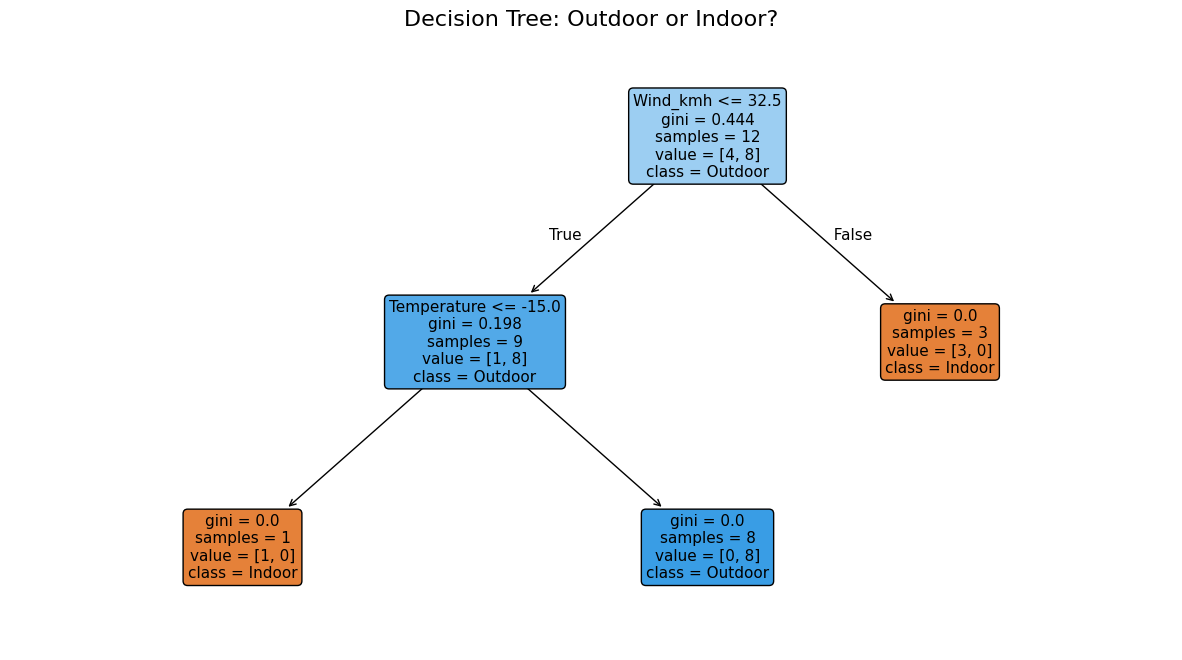

In [ ]:


# Draw the Decision Tree
plt.figure(figsize=(15, 8))

plot_tree(
    tree_model,

    # Show the feature names instead of X[0], X[1]
    feature_names=['Temperature', 'Wind_kmh'],

    # Show Indoor / Outdoor as the class names
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    fontsize=11,
    precision=3,


)

plt.title('Decision Tree: Outdoor or Indoor?', fontsize=16)
plt.show()

### Read the tree like a human

Here, in scikit-learn's tree:

- **TRUE goes to the left**
- **FALSE goes to the right**



### What do `gini`, `samples`, `value`, and `class` mean?

Each box in `plot_tree()` contains extra information about the training examples that reached that point.

**`samples`**  
How many training rows reached this box.

At the top of our tree, `samples = 12` because all 12 rows start at the root.

---

**`value`**  
How many examples of each class are in the box.

Our class order is `[Indoor, Outdoor]`, so `value = [4, 8]` means **4 Indoor** examples and **8 Outdoor** examples.

**`class`**  
The class the node would predict. Usually this is the majority class in `value`.

So `value = [4, 8]` gives `class = Outdoor`.


---  
   



**`gini`**  
Gini tells us how mixed the classes are inside a node.

- `gini = 0` → completely pure; all examples belong to one class
- higher Gini → the node contains a mixture of classes

### How is Gini calculated?
Formula is:

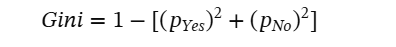


Gini tells us how mixed the classes are inside a node.

For this node, we have **12 samples in total**:

- 4 are **Indoor**
- 8 are **Outdoor**

So:

- `4/12` means **4 out of 12 samples are Indoor**
- `8/12` means **8 out of 12 samples are Outdoor**

We use those numbers in the Gini formula:

`Gini = 1 - (4/12)² - (8/12)²`

`= 1 - 0.111 - 0.444`

`≈ 0.444`

That is why the root shows `gini = 0.444`.

At a pure leaf such as `value = [3, 0]`:

`Gini = 1 - (3/3)² - (0/3)² = 0`

So the node is completely Indoor.

---

### What do `filled=True` and `rounded=True` mean?

These only change how the tree looks.

- `filled=True` → colours the boxes based on the predicted class / class mixture
- `rounded=True` → gives the boxes rounded corners

They do **not** change the trained model or its predictions.


### What does the tree show?

The first question in this tree is about **wind speed**. In our small dataset, very windy days tend to lead toward an **Indoor** prediction.

For calmer days, the model then checks the **temperature**. The final boxes, called **leaf nodes**, contain the model's prediction.

This is the main idea of a decision tree: **one question leads to another until the model reaches a decision**.


## 2.5 Make a prediction

Suppose we have a winter day with:

- Temperature = **−7 °C**
- Wind speed = **20 km/h**

Before running the code, guess:

**Do you think the tree will predict Outdoor or Indoor?**


In [ ]:
# Create one new winter day
new_winter_day = pd.DataFrame({
    'Temperature': [-7],
    'Wind_kmh': [20]
})

new_winter_day


,Temperature,Wind_kmh
0,-7,20


In [ ]:
# Ask the trained tree to classify the new day
activity_prediction = tree_model.predict(new_winter_day)

print("Predicted activity:", activity_prediction[0])


Predicted activity: Outdoor


### What does the result mean?

The model predicts **Outdoor** for this example.

The prediction comes from the sequence of rules in the tree. The model checks the values for wind speed and temperature, follows the matching branches, and ends at an Outdoor leaf.


# Exercise 3: Change the weather

Before changing the code, predict the answer yourself.

1. What do you think happens at **−16 °C with 10 km/h wind**?
2. What do you think happens at **−5 °C with 42 km/h wind**?
3. Change one feature at a time. Which feature seems to change the prediction more easily?
4. Follow the tree diagram and see if you can explain **why** the prediction changed.


In [ ]:
# Try different values here
try_winter_day = pd.DataFrame({
    'Temperature': [-16],
    'Wind_kmh': [10]
})

print("Predicted activity:", tree_model.predict(try_winter_day)[0])


Predicted activity: Indoor


## 2.6 Why is a Decision Tree different from Linear Regression?

In the Linear Regression example, the model learned a **line** and predicted a numerical value.

Here, the Decision Tree learns a sequence of **if-this-then-that style rules** and predicts a category.

For example, a tree can learn patterns similar to:

**Is the wind very strong? → If yes, go one way. If no, check the temperature next.**


# Exercise 4: Winter Coat Choice

Now try a second everyday winter example.

The synthetic dataset below contains:

- **Temperature**
- **Wind speed**
- the type of coat chosen: **Light** or **Winter**

Your task is to build a Decision Tree model that predicts the coat category.

Before writing the model, answer these questions:

1. What should **X** contain?
2. What should **y** contain?
3. Looking at the table, what pattern do you notice?
4. For **3 °C and 32 km/h wind**, would you guess Light or Winter?
5. Build the tree and test your guess.


In [ ]:
# Synthetic practice data
coat = pd.DataFrame({
    'Temperature': [12, 10, 8, 6, 5, 4, 2, 0, -3, -6, -10],
    'Wind_kmh':    [10, 20, 15, 30, 10, 35, 20, 10, 30, 15, 25],
    'Coat': [
        'Light', 'Light', 'Light', 'Winter', 'Light',
        'Winter', 'Winter', 'Winter', 'Winter', 'Winter', 'Winter'
    ]
})

coat


,Temperature,Wind_kmh,Coat
0,12,10,Light
1,10,20,Light
2,8,15,Light
3,6,30,Winter
4,5,10,Light
5,4,35,Winter
6,2,20,Winter
7,0,10,Winter
8,-3,30,Winter
9,-6,15,Winter


In [ ]:
# Write your solution below.
# Suggested steps:
# 1. Choose X and y
# 2. Create DecisionTreeClassifier()
# 3. Fit the model
# 4. Create a new row for 3 °C and 32 km/h wind
# 5. Predict the coat category


<details>
<summary><b>Click here to see the solution</b></summary>

```python
# 1. Choose X and y
X_coat = coat[['Temperature', 'Wind_kmh']]
y_coat = coat['Coat']

# 2. Create the model
coat_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# 3. Fit the model
coat_model.fit(X_coat, y_coat)

# 4. Create a new example
new_coat_day = pd.DataFrame({
    'Temperature': [3],
    'Wind_kmh': [32]
})

# 5. Predict the coat category
coat_prediction = coat_model.predict(new_coat_day)

print("Predicted coat:", coat_prediction[0])
```

The model predicts **Winter**.

In this synthetic dataset, lower temperatures usually lead to a Winter coat. For temperatures above about 4 to 5 °C, wind speed also starts to matter. That is a good example of why a decision tree is useful: it can combine more than one simple condition when making a prediction.

</details>

### After the exercise

Try changing only one value at a time.

For example:

- keep the temperature at **3 °C** and lower the wind speed
- keep the wind speed at **32 km/h** and raise the temperature

Watch when the prediction changes, then use the tree rules to explain why.


## Quick review

Before moving on, make sure you can explain these in your own words:

1. What is a Decision Tree?
2. What is the difference between a decision node and a leaf node?
3. What does `.fit()` do here?
4. What does `.predict()` do here?
5. Why did we use `max_depth=3`?
6. How is this different from the Linear Regression example?


<details>
<summary><b>Answers</b></summary>

1. What is a Decision Tree?

   = *A model that makes predictions by following a sequence of decision rules.*

2. What is the difference between a decision node and a leaf node?

   = *A decision node asks a question about a feature. A leaf node gives the final prediction.*

3. What does `.fit()` do here?

   = *It lets the tree learn useful decision rules from the training examples.*

4. What does `.predict()` do here?

   = *It follows the learned rules to classify a new example.*

5. Why did we use `max_depth=3`?

   = *To keep the tree small and easier to read for this beginner example.*

6. How is this different from the Linear Regression example?

   = *Linear Regression predicted a number using a fitted line. This Decision Tree predicts a category by following decision rules.*

</details>


---

# 3. **Random Forests**

A **Random Forest** is a supervised machine-learning method built from **many Decision Trees**.

In the last section, we used one Decision Tree and followed one set of learned rules. A Random Forest builds several trees that are intentionally made a little different from one another, then combines their results.

A simple beginner way to think about it is:

> **One Decision Tree = one opinion**  
> **Random Forest = a group decision**

Random Forest can be used for both **classification** and **regression**. In this section, we will use `RandomForestClassifier` because our answer will be a category: **Yes** or **No**.

To keep the example relatable, we will use a **synthetic Canadian winter scenario**: will school be closed on a snowy morning?

> Note: This is only a simplified teaching example. Real school-closure decisions can depend on many other factors.



### 3.1 Why is it called a **Random** Forest?

The trees are made different in two main ways:

1. **Random training rows**  
   Each tree learns from a random sample of the training data. Some rows may appear more than once, while others may not appear in that tree's sample.

2. **Random features at each split**  
   When a tree decides where to split, it considers only a random subset of the available features.

Because the trees don't all learn from exactly the same information, they can learn slightly different rules.

**But why is having different trees useful?**

A single Decision Tree can be sensitive to small changes in the training data. Its rules, and sometimes its predictions, may change.

A Random Forest combines predictions from several trees, so the final result is often more stable.

For example, suppose 4 out of 5 trees predict **Yes**. Even if one of those trees changes its prediction to **No**, the majority still says **Yes**.

This is what we mean by a **more stable prediction.** Combining different trees can make the final answer less sensitive to small changes in the training data.


## 3.2 Create a small dataset

We will again use a **synthetic** dataset so that every row is easy to see.

Each row is one winter morning, with the snowfall overnight, the wind speed, and whether school was closed.

Before building the model, look at the table and think:

**Which mornings were closed? Only the snowy ones? Or does the wind matter too?**


In [ ]:
# Create a small synthetic dataset of winter mornings
snow_day = pd.DataFrame({
    'Snowfall_cm': [0, 2, 3, 4, 5, 6, 7, 9, 12, 15, 18, 22],
    'Wind_kmh':    [10, 30, 15, 20, 45, 25, 20, 15, 35, 10, 40, 20],
    'School_Closed': [
        'No', 'No', 'No', 'No', 'Yes', 'No',
        'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes'
    ]
})

snow_day

,Snowfall_cm,Wind_kmh,School_Closed
0,0,10,No
1,2,30,No
2,3,15,No
3,4,20,No
4,5,45,Yes
5,6,25,No
6,7,20,Yes
7,9,15,Yes
8,12,35,Yes
9,15,10,Yes


### What do the data suggest?

Most of the closures happen when there is a lot of snow. From 7 cm upwards, every morning is closed.

But look at the row with only **5 cm of snow**. That morning was closed too, and the wind that day
was **45 km/h**, the strongest in the table.

So snowfall is not the only thing that matters. On a borderline morning, strong wind can close the
school as well. This is a good situation for a random forest, because the trees can look at both
clues together.

## 3.3 Choose the input features and the target

For this example:

- **X** has two input features: snowfall and wind speed
- **y** is the answer we want to predict: `School_Closed`, Yes or No


In [ ]:
# Select the two input features
X_forest = snow_day[['Snowfall_cm', 'Wind_kmh']]

X_forest

,Snowfall_cm,Wind_kmh
0,0,10
1,2,30
2,3,15
3,4,20
4,5,45
5,6,25
6,7,20
7,9,15
8,12,35
9,15,10


In [ ]:
# Select the category we want the model to predict
y_forest = snow_day['School_Closed']

y_forest

,School_Closed
0,No
1,No
2,No
3,No
4,Yes
5,No
6,Yes
7,Yes
8,Yes
9,Yes


## 3.4 Import and create the Random Forest model

For this section, we use one tool from `sklearn.ensemble`:

- `RandomForestClassifier` builds many Decision Trees and combines their results.

The word **ensemble** simply means a group of models working together.

Notice how little changes from the last section. We still:

**create → fit → predict**

Once you understand that workflow, trying another scikit-learn model becomes much easier.


### What do `n_estimators=5`, `max_depth=3`, and `random_state=42` mean?

- **`n_estimators=5`** → build **5 trees**. Scikit-learn's default is 100, but we use only 5 here so we can inspect every tree.
- **`max_depth=3`** → keep each tree small, just like in the Decision Tree section.
- **`random_state=42`** → make the random choices reproducible so the workshop gives the same result when the same code is run again.

The number **5** is a teaching choice, not a magic number.


In [ ]:
# Import the Random Forest model
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Create the model with 5 trees
forest_model = RandomForestClassifier(
    n_estimators=5,
    max_depth=3,
    random_state=42
)

forest_model

RandomForestClassifier(max_depth=3, n_estimators=5, random_state=42)

In [ ]:
# Train the model using the winter mornings
# Each tree learns from a random sample of the training data
forest_model.fit(X_forest, y_forest)


RandomForestClassifier(max_depth=3, n_estimators=5, random_state=42)

## 3.5 Look inside the forest

In the Decision Tree section, we drew one tree and followed its rules.

A forest contains several trees, so drawing all of them would quickly become messy. Instead, we can ask each tree what it predicts for the **same** winter morning.

Let us try:

- Snowfall = **3 cm**
- Wind = **45 km/h**

There is not much snow, but the wind is very strong.

Before running the next cells:

**Do you think all five trees will give the same answer?**


In [ ]:
# Create one new winter morning
new_morning = pd.DataFrame({
    'Snowfall_cm': [3],
    'Wind_kmh': [45]
})

new_morning

,Snowfall_cm,Wind_kmh
0,3,45


In [ ]:
# Store the five tree predictions in a list
tree_predictions = []

# Go through the trees one at a time
for one_tree in forest_model.estimators_:

    # Each tree stores the class as a number (0 or 1)
    answer_number = int(
        one_tree.predict(new_morning.to_numpy())[0]
    )

    # Convert the number back to the class name: No or Yes
    answer_word = forest_model.classes_[answer_number]

    # Add the answer to our list
    tree_predictions.append(answer_word)

# Put the tree predictions into a table
vote_table = pd.DataFrame({
    'Tree': range(1, len(tree_predictions) + 1),
    'Prediction': tree_predictions
})

vote_table


,Tree,Prediction
0,1,Yes
1,2,No
2,3,Yes
3,4,No
4,5,Yes


### What do the tree predictions show?

The five trees do **not** all agree.

For this example:

- 3 trees predict **Yes**
- 2 trees predict **No**

That is normal. Because the trees are built with randomness, they can learn different rules from the same overall dataset.

A single Decision Tree would give us only one learned set of rules. A Random Forest combines information from several trees.


## 3.6 Make the forest's final prediction

Now we ask the whole Random Forest about the same morning.

Before running the code, guess:

**If most of the trees lean toward Yes, what do you expect the forest to predict?**


In [ ]:
# Ask the trained forest about the new morning
closure_prediction = forest_model.predict(new_morning)

print("School closed?", closure_prediction[0])

School closed? Yes


### What does the result mean?

The Random Forest predicts **Yes** for this example.

For a beginner, it is useful to think of Random Forest as **many trees contributing to one final decision**.

In this example, the simple majority idea matches the final result: 3 trees predicted Yes and 2 predicted No.

> **Small technical note:** scikit-learn's `RandomForestClassifier` combines the class probabilities from the trees when it makes the final prediction. The voting idea is still a useful way to understand the main concept.


# Exercise 5: Change the weather

Before changing the code, predict the answer yourself.

1. What do you think happens with **2 cm of snow and 10 km/h wind**?
2. What do you think happens with **10 cm of snow and 15 km/h wind**?
3. Change one feature at a time. What do you notice about the prediction?
4. Can you find another morning where the trees do not all agree?


In [ ]:
# Ques 1: Try different values here
try_morning = pd.DataFrame({
    'Snowfall_cm': [2],
    'Wind_kmh': [10]
})

print("School closed?", forest_model.predict(try_morning)[0])

School closed? No


<details>
<summary><b>Click here to see the answers</b></summary>

### 1. What happens with 2 cm of snow and 10 km/h wind?

The Random Forest predicts:

**No**

The individual trees predict:

- Tree 1 → No
- Tree 2 → No
- Tree 3 → No
- Tree 4 → No
- Tree 5 → Yes

So most trees lean toward **No**.

</details>

In [ ]:
# Ques 2: Try different values here
try_morning = pd.DataFrame({
    'Snowfall_cm': [10],
    'Wind_kmh': [15]
})

print("School closed?", forest_model.predict(try_morning)[0])

School closed? Yes


<details>
<summary><b>Click here to see the answers</b></summary>

### 2. What happens with 10 cm of snow and 15 km/h wind?

The Random Forest predicts:

**Yes**

In this case, all 5 trees predict **Yes**.

</details>

In [ ]:
# Check what each tree predicts
tree_predictions = []

for one_tree in forest_model.estimators_:
    answer_number = int(
        one_tree.predict(try_morning.to_numpy())[0]
    )
    tree_predictions.append(
        forest_model.classes_[answer_number]
    )

# Show the prediction from each tree
pd.DataFrame({
    'Tree': range(1, len(tree_predictions) + 1),
    'Prediction': tree_predictions
})


,Tree,Prediction
0,1,Yes
1,2,Yes
2,3,Yes
3,4,Yes
4,5,Yes


<details>
<summary><b>Click here to see the answers</b></summary>

### 3. Change one feature at a time. What do you notice about the prediction?

For this small synthetic dataset, **changing snowfall often affects the prediction more than changing wind.** However, this exercise is mainly for exploring how the model reacts, it is not a formal feature-importance test.

But the purpose of this exercise is mainly to experiment:

- keep snowfall the same and change wind
- keep wind the same and change snowfall
- watch when the prediction changes

---

### 4. Can you find another morning where the trees do not all agree?

Yes.

Try:

- Snowfall = **0 cm**
- Wind = **40 km/h**

The trees predict:

- Tree 1 → Yes
- Tree 2 → No
- Tree 3 → Yes
- Tree 4 → No
- Tree 5 → Yes

The final Random Forest prediction is:

**Yes**

</details>

## 3.7 Decision Tree vs. Random Forest

In the Decision Tree example, the model learned **one** set of rules, and we could draw the tree and follow the path ourselves.

A Random Forest combines **many** Decision Trees. This usually makes it more stable, but it is harder to explain with one simple diagram.

| | Linear Regression | Decision Tree | Random Forest |
|---|---|---|---|
| **What it predicts here** | a number | a category | a category |
| **Main idea** | fit a line | follow one tree | combine many trees |
| **Our example** | heating use | Outdoor / Indoor | school closed / open |
| **Easy to visualize?** | yes | yes | not as a whole |
| **Main beginner takeaway** | learn a numerical trend | learn one set of rules | combine many different trees |

### The connection

**Linear Regression** → learn a line  
**Decision Tree** → learn one set of rules  
**Random Forest** → combine many Decision Trees


# Exercise 6: Outdoor Skating Rink

Now apply the same Random Forest workflow to a different winter example.

The synthetic dataset contains:

- **Temperature**
- **Snow_Last_Night_cm**
- whether the rink was open: **Yes** or **No**

Your task is to build a Random Forest model that predicts whether the rink is open.

Before writing the model:

1. What should **X** contain?
2. What should **y** contain?
3. Looking at the table, what pattern do you notice?
4. For **−7 °C and 3 cm of fresh snow**, would you guess Yes or No?
5. Build the forest and test your guess.


In [ ]:
# Synthetic practice data
rink = pd.DataFrame({
    'Temperature':        [-15, -12, -10, -8, -6, -4, -9, -11, -2, 0, 2, -5],
    'Snow_Last_Night_cm': [  0,   2,   1,  4,  0,  2,  9,  12,  1, 0, 0,  8],
    'Rink_Open': [
        'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes',
        'No',  'No',  'No',  'No',  'No',  'No'
    ]
})

rink

,Temperature,Snow_Last_Night_cm,Rink_Open
0,-15,0,Yes
1,-12,2,Yes
2,-10,1,Yes
3,-8,4,Yes
4,-6,0,Yes
5,-4,2,Yes
6,-9,9,No
7,-11,12,No
8,-2,1,No
9,0,0,No


In [ ]:
# Write your solution below.
# Suggested steps:
# 1. Choose X and y
# 2. Create RandomForestClassifier(n_estimators=5, max_depth=3, random_state=42)
# 3. Fit the model
# 4. Create a new row for -7 °C and 3 cm of fresh snow
# 5. Predict whether the rink is open

<details>
<summary><b>Click here to see the solution</b></summary>

```python
# 1. Choose X and y
X_rink = rink[['Temperature', 'Snow_Last_Night_cm']]
y_rink = rink['Rink_Open']

# 2. Create the model
rink_model = RandomForestClassifier(
    n_estimators=5,
    max_depth=3,
    random_state=42
)

# 3. Fit the model
rink_model.fit(X_rink, y_rink)

# 4. Create a new example
new_rink_day = pd.DataFrame({
    'Temperature': [-7],
    'Snow_Last_Night_cm': [3]
})

# 5. Predict whether the rink is open
rink_prediction = rink_model.predict(new_rink_day)

print("Rink open?", rink_prediction[0])
```

The model predicts **Yes**.

In this synthetic dataset, cold days with little fresh snow are open, and days with a lot of fresh
snow are closed even when it is cold. Warm days are closed as well. At −7 °C with only 3 cm of snow,
all five trees agreed on Yes.

</details>

### After the exercise

Try changing only one value at a time.

For example:

- keep the temperature at **−7 °C** and raise the fresh snow to **10 cm**
- keep the fresh snow at **3 cm** and raise the temperature to **2 °C**

Watch when the prediction changes, then try to explain why using the two clues.

## Quick review

Before moving on, make sure you can explain these in your own words:

1. What is a Random Forest?
2. Why is it called **Random** Forest?
3. How is a Random Forest related to a Decision Tree?
4. What does `n_estimators=5` mean?
5. What does `.fit()` do here?
6. Why can several trees be more stable than one tree?


<details>
<summary><b>Answers</b></summary>

1. **What is a Random Forest?**  
   = *A machine-learning model built from many Decision Trees.*

2. **Why is it called Random Forest?**  
   = *The trees are made different using random samples of training rows and random subsets of features.*

3. **How is it related to a Decision Tree?**  
   = *A Random Forest combines many Decision Trees instead of depending on only one.*

4. **What does `n_estimators=5` mean?**  
   = *Build 5 trees in the forest.*

5. **What does `.fit()` do here?**  
   = *It trains all the trees in the forest using the training data.*

6. **Why can several trees be more stable than one tree?**  
   = *Different trees can learn different rules, so the final result does not depend on only one tree.*

</details>


# 4. **K-Nearest Neighbours (KNN)**

**K-Nearest Neighbours (KNN)** is a supervised machine-learning method that makes a prediction by looking at the **most similar examples it has already seen**.

For a new data point, KNN:

1. finds the closest examples in the training data
2. looks at their classes
3. uses the most common class as the prediction

The **K** in KNN tells us **how many neighbours to look at**.

For example:

`K = 3`

means:

> Look at the **3 closest examples** before making the prediction.

## 4.1 Think of KNN like asking your neighbours

Imagine we want to predict whether grocery-delivery demand on a winter day will be **High** or **Normal**.

We already know what happened on several previous winter days.

Now a new day comes.

Instead of creating a rule such as:

> "If snowfall is above this number, predict High"

KNN asks:

> **Which previous days were most similar to this new day?**

If most of the closest days had **High** demand, KNN predicts **High**.

If most had **Normal** demand, KNN predicts **Normal**.

## 4.2 Create a small winter dataset

We will use a small **synthetic** dataset so that we can see every example clearly.

Each row represents a previous winter day.

We will use:

- **Temperature** in °C
- **Snowfall** in cm

to predict grocery-delivery demand:

- **Normal**
- **High**

Before we use KNN, look at the data and see if you notice any pattern.

In [ ]:
# Create a small synthetic winter dataset

delivery = pd.DataFrame({
    'Temperature': [2, 0, -2, -4, -6, -8, -10, -12],
    'Snowfall_cm': [0, 1, 2, 4, 5, 7, 9, 12],
    'Demand': [
        'Normal',
        'Normal',
        'Normal',
        'Normal',
        'High',
        'High',
        'High',
        'High'
    ]
})

delivery

,Temperature,Snowfall_cm,Demand
0,2,0,Normal
1,0,1,Normal
2,-2,2,Normal
3,-4,4,Normal
4,-6,5,High
5,-8,7,High
6,-10,9,High
7,-12,12,High


### Before we build the model

Suppose tomorrow is:

- Temperature = **−7 °C**
- Snowfall = **6 cm**

What would you predict?

**Normal** or **High**?

Don't calculate anything yet.

First, look at the previous days in the table and ask:

> **Which days look most similar to this new day?**

That is the basic idea behind KNN.

## 4.3 Choose the input features and the target

Just like the previous supervised-learning methods:

- **X** contains the information we give to the model
- **y** contains the class we want the model to predict

For this example:

- **X** = Temperature and Snowfall
- **y** = Grocery-delivery demand: Normal or High

In [ ]:
# Select the input features

X_knn = delivery[
    ['Temperature', 'Snowfall_cm']
]

X_knn

,Temperature,Snowfall_cm
0,2,0
1,0,1
2,-2,2
3,-4,4
4,-6,5
5,-8,7
6,-10,9
7,-12,12


In [ ]:
# Select the target we want to predict

y_knn = delivery['Demand']

y_knn

,Demand
0,Normal
1,Normal
2,Normal
3,Normal
4,High
5,High
6,High
7,High


## 4.4 How does KNN know which examples are "close"?

KNN measures the **distance** between the new data point and the examples it already has.

For two features, we can use **Euclidean distance**.

A simple way to think about it is:

> Find the difference for each feature, square those differences, add them together, and take the square root.

For our example:

New day:

- Temperature = **−7 °C**
- Snowfall = **6 cm**

One previous day:

- Temperature = **−6 °C**
- Snowfall = **5 cm**


The distance is:

$$
\text{Distance} = \sqrt{(-7 - (-6))^2 + (6 - 5)^2}
$$

Step by step:

$$
= \sqrt{(-1)^2 + 1^2}
$$

$$
= \sqrt{1 + 1}
$$

$$
= \sqrt{2}
$$

$$
\approx 1.41
$$

A **smaller distance** means the two days are more similar.


In [ ]:
# Our new winter day

new_temperature = -7
new_snowfall = 6


# Make a copy so we do not change the original dataset

distance_table = delivery.copy()


# Calculate the distance from the new day
# to every previous day

distance_table['Distance'] = (
    (distance_table['Temperature'] - new_temperature) ** 2
    +
    (distance_table['Snowfall_cm'] - new_snowfall) ** 2
) ** 0.5


# Show the closest days first

distance_table = distance_table.sort_values(
    'Distance'
)

distance_table

,Temperature,Snowfall_cm,Demand,Distance
5,-8,7,High,1.414214
4,-6,5,High,1.414214
3,-4,4,Normal,3.605551
6,-10,9,High,4.242641
2,-2,2,Normal,6.403124
7,-12,12,High,7.810250
1,0,1,Normal,8.602325
0,2,0,Normal,10.816654


### What does the distance table show?

The closest three previous days are:

| Temperature | Snowfall | Demand |
|---|---:|---|
| −6 °C | 5 cm | High |
| −8 °C | 7 cm | High |
| −4 °C | 4 cm | Normal |

If we use:

`K = 3`

KNN looks at these **3 nearest neighbours**.

Their classes are:

- High
- High
- Normal

So:

**High = 2**  
**Normal = 1**

The majority is **High**.

Therefore, we expect KNN to predict:

**High**

## 4.5 Visualize the neighbours

KNN is easier to understand when we can **see the data points**.

Each dot below represents a previous winter day.

The star represents our new day:

- Temperature = **−7 °C**
- Snowfall = **6 cm**

Look at which points are closest to the star.

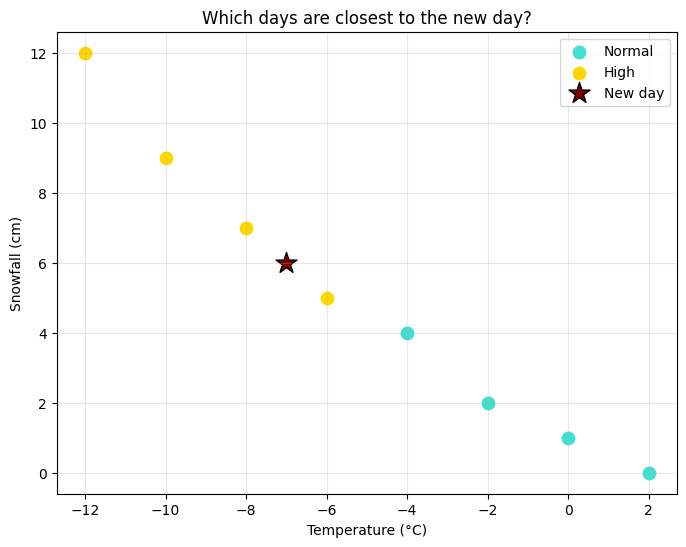

In [ ]:
# Separate the Normal and High demand days

normal_days = delivery[
    delivery['Demand'] == 'Normal'
]

high_days = delivery[
    delivery['Demand'] == 'High'
]


# Create the graph

plt.figure(figsize=(8, 6))


# Plot Normal demand days

plt.scatter(
    normal_days['Temperature'],
    normal_days['Snowfall_cm'],
    label='Normal',
    color='turquoise',
    s=80
)


# Plot High demand days

plt.scatter(
    high_days['Temperature'],
    high_days['Snowfall_cm'],
    label='High',
    color='gold',
    s=80
)


# Plot the new day as a star

plt.scatter(
    -7,
    6,
    marker='*',
    s=250,
    label='New day',
    color='maroon',
    edgecolor='black'
)


plt.xlabel('Temperature (°C)')
plt.ylabel('Snowfall (cm)')
plt.title('Which days are closest to the new day?')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 4.6 Create the KNN model

Now that we understand the idea manually, we can let scikit-learn do the work for us.

We use:

`KNeighborsClassifier`

because we are predicting a **category**:

- Normal
- High

We will start with:

`n_neighbors=3`

This means:

> Look at the **3 nearest neighbours** when making a prediction.

In [ ]:
# Import the KNN classifier

from sklearn.neighbors import KNeighborsClassifier

### Why are we using K = 3?

There is no rule saying K must always be 3.

We are using **3** because it is small and easy to understand for this example.

With two classes, using an odd number such as 3 can also help avoid a tie.

For example:

3 neighbours:

- High
- High
- Normal

There is a clear majority:

**High**

In real machine-learning projects, different values of K can be tested to find a value that works well for the data.

In [ ]:
# Create the KNN model

knn_model = KNeighborsClassifier(
    n_neighbors=3
)

knn_model

KNeighborsClassifier(n_neighbors=3)

## 4.7 Train the model

We use `.fit(X, y)` again, just like the previous supervised-learning methods.

However, KNN works a little differently.

Linear Regression learns a line.

A Decision Tree learns decision rules.

KNN mainly **keeps the training examples so it can compare new data with them later**.

In [ ]:
# Train the KNN model

knn_model.fit(
    X_knn,
    y_knn
)

KNeighborsClassifier(n_neighbors=3)

## 4.8 Make a prediction

Now let's give the model the same new winter day:

- Temperature = **−7 °C**
- Snowfall = **6 cm**

Before running the code, remember what we found manually:

The three nearest neighbours were:

**High, High, Normal**

What do you expect the prediction to be?

In [ ]:
# Create the new winter day

new_day = pd.DataFrame({
    'Temperature': [-7],
    'Snowfall_cm': [6]
})


# Ask the KNN model to predict the demand

knn_prediction = knn_model.predict(
    new_day
)


print(
    "Predicted Delivery Demand:",
    knn_prediction[0]
)

Predicted Delivery Demand: High


### What does the result mean?

The KNN model predicts:

**High**

Why?

Because the 3 closest previous days were:

- High
- High
- Normal

Most of the nearest neighbours were **High**.

So the model predicts **High** for the new day.

This is the main idea behind KNN:

> **Find similar examples → look at their classes → use the majority class.**

## 4.9 Which neighbours did the model actually use?

We already found the neighbours manually.

Now let's ask scikit-learn to show us the same information.

The `.kneighbors()` function gives us:

- the distances
- the row numbers of the nearest neighbours

In [ ]:
# Find the 3 nearest neighbours

distances, neighbour_rows = knn_model.kneighbors(
    new_day
)


# Select those rows from our original dataset

nearest_neighbours = delivery.iloc[
    neighbour_rows[0]
].copy()


# Add their distance from the new day

nearest_neighbours['Distance'] = distances[0]


nearest_neighbours

,Temperature,Snowfall_cm,Demand,Distance
4,-6,5,High,1.414214
5,-8,7,High,1.414214
3,-4,4,Normal,3.605551


### What should we notice?

The model found the same nearest examples that we saw in our distance table.

This is useful because now we can connect:

**the idea → the mathematics → the scikit-learn model**

KNN is not randomly guessing.

It is comparing the new example with the training examples using distance.

# Exercise 7: What happens when K changes?

So far we used:

`K = 3`

But what happens if we change K?

Try:

- `K = 1`
- `K = 3`
- `K = 5`

Before running each one, make a guess.

### Think about this

If `K = 1`, the model listens to only **one neighbour**.

If K becomes larger, the model listens to **more neighbours**.

How might that change the prediction?

In [ ]:
# Change this value and run the cell again

k_value = 5


# Create a new KNN model

test_knn = KNeighborsClassifier(
    n_neighbors=k_value
)


# Train the model

test_knn.fit(
    X_knn,
    y_knn
)


# Predict the same winter day

print(
    "K =", k_value
)

print(
    "Prediction:",
    test_knn.predict(new_day)[0]
)

K = 5
Prediction: High


### Why does choosing K matter?

A very small K can make the model depend too much on one unusual data point.

For example:

`K = 1`

means one neighbour makes the entire decision.

A much larger K looks at more examples, which can make the prediction less sensitive to one unusual point.

But if K becomes too large, the model may include examples that are not very similar to the new point.

So choosing K involves a balance.

# Exercise 8: Predict a different winter day

Suppose a new day has:

- Temperature = **−1 °C**
- Snowfall = **1 cm**

Before running any code:

1. Look at the original dataset.
2. Guess whether demand will be **Normal** or **High**.
3. Create the new day.
4. Use the existing `knn_model` to make the prediction.
5. Check its 3 nearest neighbours.

Write your code below.

In [ ]:
# Create the new day

practice_day = pd.DataFrame({
    'Temperature': [____],
    'Snowfall_cm': [____]
})


# Make a prediction

practice_prediction = knn_model.predict(
    practice_day
)


print(
    "Predicted demand:",
    practice_prediction[0]
)

NameError: name '____' is not defined

<details>
<summary><b>Click here to see the solution</b></summary>

```python
# Create the new day

practice_day = pd.DataFrame({
    'Temperature': [-1],
    'Snowfall_cm': [1]
})


# Make a prediction

practice_prediction = knn_model.predict(
    practice_day
)


print(
    "Predicted demand:",
    practice_prediction[0]
)


# Check the 3 nearest neighbours

distances, neighbour_rows = knn_model.kneighbors(
    practice_day
)


practice_neighbours = delivery.iloc[
    neighbour_rows[0]
].copy()


practice_neighbours['Distance'] = distances[0]


practice_neighbours
```

The model predicts **Normal**.

The 3 nearest neighbours are all **Normal**, so the final prediction is **Normal**.

</details>

### One important note about KNN

KNN makes decisions using **distance**.

That means the size and scale of the numbers can matter.

For this small teaching example, Temperature and Snowfall have reasonably similar numerical ranges, so we are keeping the example simple.

In real projects, features often need to be **scaled** before using KNN.

We will not go into feature scaling here because the goal of this section is to understand the basic KNN idea.

## Quick review

Before moving on, make sure you can explain these in your own words:

1. What does KNN do?
2. What does the **K** mean?
3. How does KNN decide which examples are closest?
4. What does `n_neighbors=3` mean?
5. What does `.fit()` do in KNN?
6. How does KNN choose the final class?

<details>
<summary><b>Answers</b></summary>

1. **What does KNN do?**

   = *It predicts a new example by looking at similar training examples nearby.*

2. **What does the K mean?**

   = *The number of nearest neighbours the model will use.*

3. **How does KNN decide which examples are closest?**

   = *It measures the distance between the new example and the training examples.*

4. **What does `n_neighbors=3` mean?**

   = *Use the 3 nearest neighbours.*

5. **What does `.fit()` do in KNN?**

   = *It stores the labelled training examples so they can be used when a new prediction is made.*

6. **How does KNN choose the final class?**

   = *It looks at the classes of the nearest neighbours and chooses the most common one.*

</details>

# 5. **K-Means Clustering**

**K-Means Clustering** is an **unsupervised machine-learning method** that groups similar data points together.

Unlike the methods we used earlier, K-Means does **not** start with a correct answer or class label.

Instead, it looks at the data and asks:

> **Which data points seem similar enough to belong together?**

Each group found by K-Means is called a **cluster**.

The **K** tells us how many clusters we want the model to create.

For example:

`K = 3`

means:

> Divide the data into **3 groups**.

## 5.1 What is different this time?

So far, our models had a **target** we wanted to predict.

For example:

- Linear Regression → predict heating use
- Decision Tree → predict Indoor or Outdoor
- Random Forest → predict Yes or No
- KNN → predict Normal or High

Those are **supervised-learning** examples because the training data already contains the correct answers.

K-Means is different.

With K-Means:

- there is **no target `y`**
- there are **no class labels**
- the model tries to discover groups by itself

This is called **unsupervised learning**.

## 5.2 A simple winter-weather example

Suppose we collected information about several winter days.

For each day, we know:

- **Temperature** in °C
- **Snowfall** in cm

But we have **not labelled the days** as mild, snowy, cold, or anything else.

We simply want to know:

> **Do some of these winter days naturally look similar to each other?**

K-Means can look at the values and group similar days into clusters.

We will use a small **synthetic dataset** so that every point is easy to see.

In [ ]:
# Create a small synthetic winter-weather dataset

winter_days = pd.DataFrame({
    'Temperature': [
         6,  4,  3,  5,
        -3, -5, -4, -6,
       -12,-14,-11,-15
    ],

    'Snowfall_cm': [
        0, 1, 0, 2,
        4, 5, 6, 4,
        9, 11, 8, 10
    ]
})

winter_days

,Temperature,Snowfall_cm
0,6,0
1,4,1
2,3,0
3,5,2
4,-3,4
5,-5,5
6,-4,6
7,-6,4
8,-12,9
9,-14,11


### Before we build the model

Look at the table first.

Do you notice any groups?

For example:

- some days are relatively warm with little snow
- some are colder with moderate snow
- some are very cold with heavier snow

There are no labels telling us what these groups are.

We are only looking for **similar patterns in the data**.

That is exactly what K-Means is designed to do.

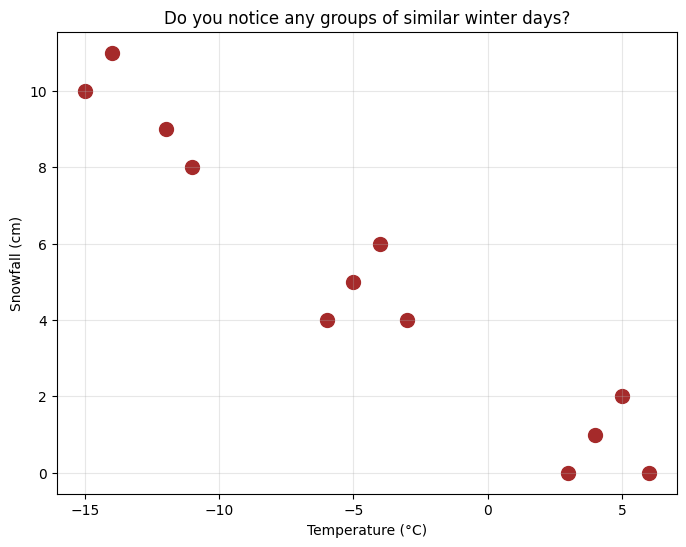

In [ ]:
# Plot the winter days

plt.figure(figsize=(8, 6))

plt.scatter(
    winter_days['Temperature'],
    winter_days['Snowfall_cm'],
    s=100,
    color='brown'
)

plt.xlabel('Temperature (°C)')
plt.ylabel('Snowfall (cm)')
plt.title('Do you notice any groups of similar winter days?')

plt.grid(alpha=0.3)

plt.show()

## 5.3 What is a cluster?

A **cluster** is simply a group of data points that are similar to each other.

In our winter-weather example, K-Means might discover groups such as:

- warmer days with very little snow
- colder days with some snow
- very cold days with heavier snow

But remember:

K-Means does **not** know these names.

It only creates groups based on how close the data points are to each other.

## 5.4 What is a centroid?

Each cluster has a **centroid**.

A centroid is the **center point of a cluster**.

You can think of it as the average location of all the points in that group.

For example, if several winter days in one cluster are around:

- Temperature = −5 °C
- Snowfall = 5 cm

then the centroid may be somewhere near those values.

K-Means uses these centroids to decide which cluster each data point belongs to.

## 5.5 How does K-Means work?

K-Means repeats a simple process:

### Step 1
Choose how many clusters we want.

For example:

`K = 3`

means:

> Create 3 clusters.

### Step 2
Start with 3 possible cluster centers.

### Step 3
Assign each data point to the closest center.

### Step 4
Move each center to the middle of the points assigned to it.

### Step 5
Repeat the process until the clusters stop changing much.

So the basic idea is:

> **Assign points → move centers → repeat**

## 5.6 Create the K-Means model

We will use:

`KMeans`

from scikit-learn.

For this example, we will create:

`3 clusters`

because our graph appears to contain roughly three natural groups.

We will use:

- `n_clusters=3` → create 3 clusters
- `random_state=42` → make the result reproducible
- `n_init=10` → try several starting positions and keep a good result

### What does `n_init=10` mean?

K-Means needs starting positions for its cluster centers.

Different starting positions can sometimes produce slightly different clusters.

`n_init=10`

means:

> Try the clustering process 10 times with different starting positions and keep the best result.

For this beginner example, you do not need to calculate this yourself.

Scikit-learn handles it for us.

In [ ]:
# Import the K-Means model

from sklearn.cluster import KMeans

In [ ]:
# Create the K-Means model

kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_model

KMeans(n_clusters=3, n_init=10, random_state=42)

## 5.7 What data do we give to K-Means?

Notice something important:

There is **no y** this time.

In supervised learning, we usually had:

- X = input features
- y = correct answer / target

But K-Means is **unsupervised**.

There is no correct answer column.

So we only give the model the features we want it to use for finding groups.

In [ ]:
# Select the features we want K-Means to use

X_kmeans = winter_days[
    ['Temperature', 'Snowfall_cm']
]

X_kmeans

,Temperature,Snowfall_cm
0,6,0
1,4,1
2,3,0
3,5,2
4,-3,4
5,-5,5
6,-4,6
7,-6,4
8,-12,9
9,-14,11


## 5.8 Find the clusters

We use `.fit()` again.

But this time, `.fit()` does something different.

There is no target y to learn from.

Instead, K-Means looks at the input data and tries to find groups of similar points.

In [ ]:
# Find 3 clusters in the winter-weather data

kmeans_model.fit(
    X_kmeans
)

KMeans(n_clusters=3, n_init=10, random_state=42)

## 5.9 Which cluster did each day join?

After fitting the model, K-Means gives each data point a **cluster number**.

Because we created 3 clusters, the labels will be:

- Cluster 0
- Cluster 1
- Cluster 2

These numbers are only names.

For example:

`Cluster 0`

does not mean "better" or "first".

It is simply the label scikit-learn assigned to that group.

In [ ]:
# Add the cluster number to the table

winter_days['Cluster'] = kmeans_model.labels_

winter_days

,Temperature,Snowfall_cm,Cluster
0,6,0,2
1,4,1,2
2,3,0,2
3,5,2,2
4,-3,4,0
5,-5,5,0
6,-4,6,0
7,-6,4,0
8,-12,9,1
9,-14,11,1


### What should we notice?

Days with similar temperature and snowfall values are placed into the same cluster.

K-Means created these groups **without being given any labels beforehand**.

That is the key difference between supervised and unsupervised learning.

## 5.10 Visualize the clusters

Now let's colour the data points according to the clusters K-Means found.

We will also show the **centroids** using large star markers.

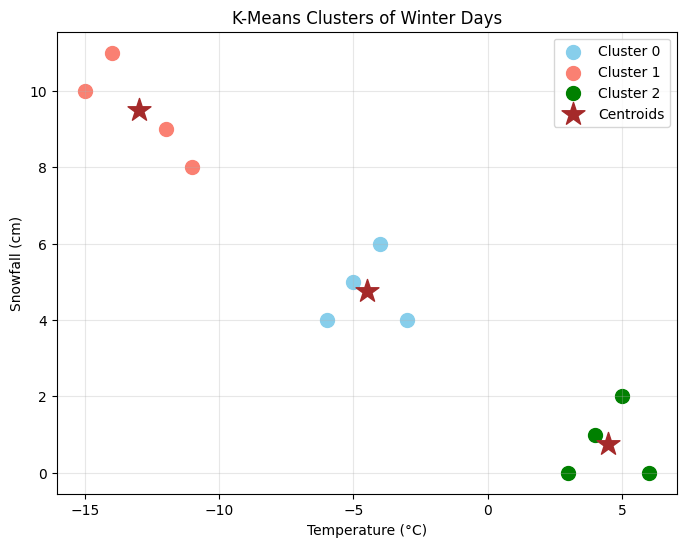

In [ ]:
# Get the coordinates of the cluster centers

centers = kmeans_model.cluster_centers_


# Create the graph

plt.figure(figsize=(8, 6))


# Plot Cluster 0

cluster_0 = winter_days[
    winter_days['Cluster'] == 0
]

plt.scatter(
    cluster_0['Temperature'],
    cluster_0['Snowfall_cm'],
    s=100,
    color='skyblue',
    label='Cluster 0'
)


# Plot Cluster 1

cluster_1 = winter_days[
    winter_days['Cluster'] == 1
]

plt.scatter(
    cluster_1['Temperature'],
    cluster_1['Snowfall_cm'],
    s=100,
    color='salmon',
    label='Cluster 1'
)


# Plot Cluster 2

cluster_2 = winter_days[
    winter_days['Cluster'] == 2
]

plt.scatter(
    cluster_2['Temperature'],
    cluster_2['Snowfall_cm'],
    s=100,
    color='green',
    label='Cluster 2'
)


# Plot the cluster centers

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='*',
    s=300,
    color='brown',
    label='Centroids'
)


plt.xlabel('Temperature (°C)')
plt.ylabel('Snowfall (cm)')
plt.title('K-Means Clusters of Winter Days')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### What does the graph show?

The coloured dots represent the three groups found by K-Means.

The brown stars represent the **centroids**.

Each data point belongs to the cluster whose centroid is closest to it.

For this synthetic dataset, we can roughly interpret the groups as:

- warmer days with little snow
- colder days with moderate snow
- very cold days with heavier snow

But remember:

K-Means did **not** create those names.

We are interpreting the clusters after the model found them.

## 5.11 Look at the centroids

The model stores the center of each cluster.

Let's look at those values directly.

In [ ]:
# Put the centroid values into a table

centroid_table = pd.DataFrame(
    centers,
    columns=['Temperature', 'Snowfall_cm']
)

centroid_table

,Temperature,Snowfall_cm
0,-4.5,4.75
1,-13.0,9.50
2,4.5,0.75


### How do we read this table?

Each row represents the center of one cluster.

For example, if one centroid is approximately:

- Temperature = −4.5 °C
- Snowfall = 4.8 cm

that means the days in that cluster tend to be around those values.

The centroid is not necessarily one real day from the dataset.

It represents the **average center of the group**.

# Exercise 9: What happens if K changes?

So far we used:

`K = 3`

But we chose that value.

What happens if we ask K-Means to create a different number of groups?

Try:

- `K = 2`
- `K = 3`
- `K = 4`

Before running each one:

> How many clusters do you expect to see?

In [ ]:
# Change this number and run the cell again

k_value = 2


# Create a new K-Means model

test_kmeans = KMeans(
    n_clusters=k_value,
    random_state=42,
    n_init=10
)


# Find the clusters

test_kmeans.fit(
    X_kmeans
)


# Print the cluster assigned to each point

print(
    "K =", k_value
)

print(
    "Cluster labels:",
    test_kmeans.labels_
)

K = 2
Cluster labels: [1 1 1 1 0 0 0 0 0 0 0 0]


### What should we learn from this?

The number of clusters depends on the value of **K** that we choose.

If:

`K = 2`

the model must divide the data into 2 groups.

If:

`K = 4`

the model must divide the same data into 4 groups.

K-Means does **not automatically know the perfect number of clusters** just because we run the model.

Choosing K is an important part of using K-Means.

# Exercise 10: Group café customers

A café has information about several customers:

- how many times they visit each month
- how much they spend per visit

There are **no customer-type labels**.

We want K-Means to find groups of similar customers.

Your task:

1. Create the dataset.
2. Select the two features.
3. Create a K-Means model with `K = 3`.
4. Fit the model.
5. Add the cluster labels to the table.
6. Look at the groups and describe what you notice.

In [ ]:
# Synthetic café-customer data

customers = pd.DataFrame({
    'Visits_per_month': [
        1, 2, 2, 3,
        5, 6, 6, 7,
        10, 11, 12, 13
    ],

    'Spend_per_visit': [
        8, 10, 12, 9,
        18, 20, 22, 19,
        30, 32, 35, 33
    ]
})

customers

,Visits_per_month,Spend_per_visit
0,1,8
1,2,10
2,2,12
3,3,9
4,5,18
5,6,20
6,6,22
7,7,19
8,10,30
9,11,32


In [ ]:
# Write your solution below.

# 1. Select the features


# 2. Create KMeans with 3 clusters


# 3. Fit the model


# 4. Add the cluster labels to the table


# 5. Display the table

<details>
<summary><b>Click here to see the solution</b></summary>

```python
# Select the features

X_customers = customers[
    ['Visits_per_month', 'Spend_per_visit']
]


# Create the model

customer_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)


# Find the clusters

customer_model.fit(
    X_customers
)


# Add the cluster labels

customers['Cluster'] = customer_model.labels_


# Show the result

customers
```

The model creates **3 clusters** of customers with similar visiting and spending patterns.

In this synthetic example, the groups roughly represent:

- customers who visit less often and spend less per visit
- customers with moderate visits and spending
- customers who visit more often and spend more per visit

Remember: K-Means did **not** create these descriptions. We interpret the clusters after looking at the results.

</details>

### One important note about K-Means

Like KNN, K-Means uses **distance**.

This means the scale of the features can affect the clusters.

For our small teaching examples, the feature ranges are simple enough to keep the demonstration easy.

In real machine-learning projects, features are often **scaled** before applying K-Means.

We will not cover scaling in detail here because our goal is to understand the basic clustering idea.

## Quick review

Before finishing this section, make sure you can explain these in your own words:

1. What is K-Means?
2. Why is K-Means unsupervised?
3. What does K mean?
4. What is a cluster?
5. What is a centroid?
6. Why don't we have a target `y`?

<details>
<summary><b>Answers</b></summary>

1. **What is K-Means?**

   = *A machine-learning method that groups similar data points together.*

2. **Why is K-Means unsupervised?**

   = *Because the training data does not contain correct class labels or target answers.*

3. **What does K mean?**

   = *The number of clusters we want the model to create.*

4. **What is a cluster?**

   = *A group of similar data points.*

5. **What is a centroid?**

   = *The center of a cluster.*

6. **Why don't we have a target `y`?**

   = *Because K-Means is trying to discover groups instead of predicting a known target.*

</details>

# Quick comparison of the five techniques

We have now seen five different machine-learning methods.

| Method | Type | Main idea | Example from this notebook |
|---|---|---|---|
| **Linear Regression** | Supervised | Learn a relationship to predict a number | Heating use |
| **Decision Tree** | Supervised | Follow learned decision rules | Indoor / Outdoor |
| **Random Forest** | Supervised | Combine many Decision Trees | School closure |
| **KNN** | Supervised | Look at the nearest labelled examples | Delivery demand |
| **K-Means** | Unsupervised | Group similar data points | Winter-weather clusters |

### The big picture

**Linear Regression**

> Learn a numerical relationship.

**Decision Tree**

> Learn one set of decision rules.

**Random Forest**

> Combine many Decision Trees.

**KNN**

> Look at similar labelled examples nearby.

**K-Means**

> Discover groups without labels.

## One thing to remember about each method

| Method | One thing to remember |
|---|---|
| **Linear Regression** | Unusual data points can affect the fitted line. |
| **Decision Tree** | A very large tree can become difficult to understand and may learn the training data too closely. |
| **Random Forest** | Combining many trees can make predictions more stable, but the whole model is harder to visualize. |
| **KNN** | The choice of K and the scale of the features can affect the result. |
| **K-Means** | We choose the number of clusters, and we interpret what the clusters mean after the model finds them. |

### Putting everything together

The diagram below summarizes how the five methods fit together.

> **Note:** This plotting code is only used to create the summary diagram. You do not need to understand or reproduce the plotting code for this session.

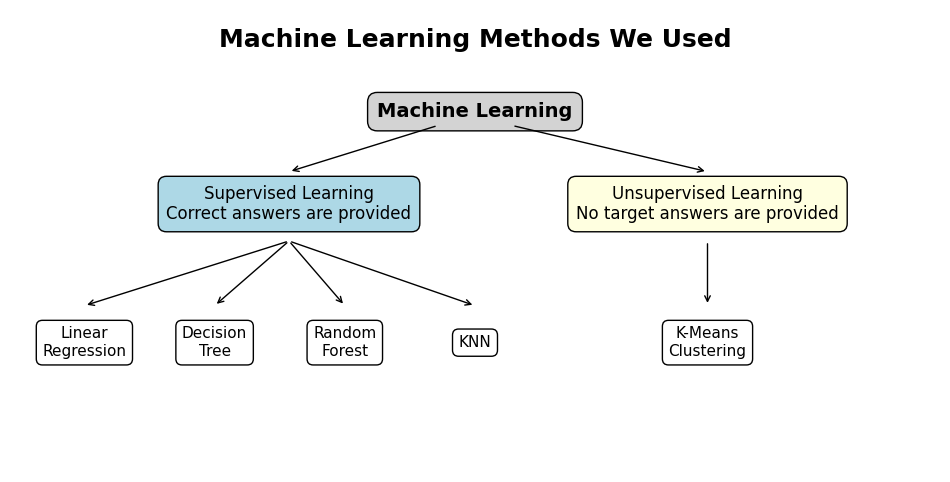

In [ ]:
#just showcasing it with visuals

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.axis('off')


# Main title
plt.text(
    0.5, 0.92,
    'Machine Learning Methods We Used',
    ha='center',
    fontsize=18,
    fontweight='bold'
)


# Machine Learning box
plt.text(
    0.5, 0.78,
    'Machine Learning',
    ha='center',
    va='center',
    fontsize=14,
    fontweight='bold',
    bbox=dict(
        boxstyle='round,pad=0.5',
        facecolor='lightgray'
    )
)


# Supervised Learning box
plt.text(
    0.30, 0.58,
    'Supervised Learning\nCorrect answers are provided',
    ha='center',
    va='center',
    fontsize=12,
    bbox=dict(
        boxstyle='round,pad=0.5',
        facecolor='lightblue'
    )
)


# Unsupervised Learning box
plt.text(
    0.75, 0.58,
    'Unsupervised Learning\nNo target answers are provided',
    ha='center',
    va='center',
    fontsize=12,
    bbox=dict(
        boxstyle='round,pad=0.5',
        facecolor='lightyellow'
    )
)


# Supervised methods
supervised_methods = [
    'Linear\nRegression',
    'Decision\nTree',
    'Random\nForest',
    'KNN'
]

x_positions = [0.08, 0.22, 0.36, 0.50]

for x, method in zip(x_positions, supervised_methods):
    plt.text(
        x, 0.28,
        method,
        ha='center',
        va='center',
        fontsize=11,
        bbox=dict(
            boxstyle='round,pad=0.4',
            facecolor='white'
        )
    )


# K-Means
plt.text(
    0.75, 0.28,
    'K-Means\nClustering',
    ha='center',
    va='center',
    fontsize=11,
    bbox=dict(
        boxstyle='round,pad=0.4',
        facecolor='white'
    )
)


# Arrows from Machine Learning
plt.annotate(
    '',
    xy=(0.30, 0.65),
    xytext=(0.46, 0.75),
    arrowprops=dict(arrowstyle='->')
)

plt.annotate(
    '',
    xy=(0.75, 0.65),
    xytext=(0.54, 0.75),
    arrowprops=dict(arrowstyle='->')
)


# Arrows to the individual methods
for x in x_positions:
    plt.annotate(
        '',
        xy=(x, 0.36),
        xytext=(0.30, 0.50),
        arrowprops=dict(arrowstyle='->')
    )

plt.annotate(
    '',
    xy=(0.75, 0.36),
    xytext=(0.75, 0.50),
    arrowprops=dict(arrowstyle='->')
)


plt.show()

## Supervised vs. Unsupervised

The diagram above shows the biggest difference:

### Supervised Learning
We already know the correct answers during training.

**Linear Regression → Decision Tree → Random Forest → KNN**

### Unsupervised Learning
There is no target answer. The model looks for patterns in the data.

**K-Means Clustering**

### Easy way to remember

> **Supervised:** “Here are examples AND their answers. Learn from them.”

> **Unsupervised:** “Here are the data. See what patterns you can find.”

# Session 2 complete

In this session, we moved from machine-learning concepts to practical code.

You have now seen how to:

- create small datasets
- choose input features and targets
- create scikit-learn models
- train models using `.fit()`
- make predictions using `.predict()`
- understand Decision Trees and Random Forests
- classify using nearest neighbours
- discover groups using K-Means clustering

> **One last note:** Every dataset in this notebook was **synthetic, small, and clean**, so the patterns were easier to see and understand.

Real-world datasets are usually larger and messier, and model performance needs to be evaluated carefully.

The goal of this session was to understand the **basic idea and workflow behind each technique**, not to decide which model is "best."

The next session will build on these ideas using a more complete machine-learning workflow.